# Arquivo GPX

In [39]:
import matplotlib.pyplot as plt
from dateutil.parser import parse
import datetime
import matplotlib.dates as mdates
import numpy as np

In [40]:
with open('track3.gpx') as io:
    conteudo = io.readlines()

In [41]:
type(conteudo)

list

In [42]:
len(conteudo)

1

In [43]:
type(conteudo[0])

str

In [44]:
linha = conteudo[0]
print(type(linha), len(linha))

<class 'str'> 32953


In [45]:
linha.find('</trkseg>')

32932

In [46]:
linha[-100:]

'52.231452"><ele>4.19415283203125</ele><time>2026-04-15T14:08:55Z</time></trkpt></trkseg></trk></gpx>'

In [47]:
linha.find('<trkpt')

409

In [48]:
linha.find('</trkpt')

508

## Acha a primeira sentença de trackpoint

In [49]:
inicia = '<trkpt'
termina = '</trkpt>'

i_ini = linha.find(inicia)
i_fim = linha.find(termina) + len(termina)

sentenca = linha[i_ini:i_fim]
print(sentenca)

<trkpt lat="-32.069684" lon="-52.226772"><ele>8.684326171875</ele><time>2026-04-15T12:17:46Z</time></trkpt>


In [50]:
nova_lista = sentenca.split('"')
print(nova_lista[1], nova_lista[3])

-32.069684 -52.226772


In [51]:
sentenca.find('<time>')

66

In [52]:
sentenca[sentenca.find('<time>')+6:sentenca.find('</time>')+400]

'2026-04-15T12:17:46Z</time></trkpt>'

In [53]:
str_tempo = sentenca[sentenca.find('<time>')+6:sentenca.find('</time>')]
str_tempo

'2026-04-15T12:17:46Z'

In [54]:
parse(str_tempo)

datetime.datetime(2026, 4, 15, 12, 17, 46, tzinfo=tzutc())

2026-04-15T12:17:46Z

In [55]:
inicia = '<trkpt'
termina = '</trkpt>'
i_ini = []
i_fim = []
for i in range(len(linha)):
    if linha[i:i+len(inicia)] == inicia:
        i_ini.append(i)
    if linha[i:i+len(termina)] == termina:
        i_fim.append(i)

In [56]:
linha[i_ini[0]:i_fim[0]]

'<trkpt lat="-32.069684" lon="-52.226772"><ele>8.684326171875</ele><time>2026-04-15T12:17:46Z</time>'

In [57]:
linha[i_ini[1]:i_fim[1]]

'<trkpt lat="-32.069684" lon="-52.226772"><ele>-0.374237060546875</ele><time>2026-04-15T12:17:55Z</time>'

In [58]:
latitude = []
longitude = []
tempo = []
for i in range(len(i_ini)):
    sentenca = linha[i_ini[i]:i_fim[i]]

    nova_lista = sentenca.split('"')
    str_tempo = sentenca[sentenca.find('<time>')+6:sentenca.find('</time>')]
    tempo.append(parse(str_tempo))
    latitude.append(float(nova_lista[1]))
    longitude.append(float(nova_lista[3]))
    

In [59]:
print(len(tempo), len(latitude), len(longitude))

300 300 300


In [60]:
import pickle

In [61]:
doc = '''
Dados de um arquivo GPX processados [tempo, latitude, longitude]
eu, hoje
'''
junta = [doc, 
         tempo, 
         latitude, 
         longitude]

with open('dados_GPX_reduzidos.pkl','wb') as io:
    pickle.dump(junta, io)

In [62]:
nova_lista = [1, 2, 3]
novo_dicionario = {'meta_data': doc,
                  'tempo': tempo,
                  'latitude': latitude,
                  'longitude': longitude} 

with open('dados_GPX_reduzidos_dic.pkl','wb') as io:
    pickle.dump(novo_dicionario, io)

In [63]:
with open('dados_GPX_reduzidos_tempo.pkl','wb') as io:
    pickle.dump(tempo, io)

with open('dados_GPX_reduzidos_longitude.pkl','wb') as io:
    pickle.dump(longitude, io)

with open('dados_GPX_reduzidos_latitude.pkl','wb') as io:
    pickle.dump(latitude, io)

In [64]:
who

conteudo	 datetime	 distancia	 doc	 dt	 hoje	 i	 i_fim	 i_ini	 
inicia	 io	 junta	 latitude	 linha	 longitude	 mdates	 nova_lista	 novo_dicionario	 
np	 parse	 pickle	 plt	 sentenca	 str_tempo	 tempo	 tempo_n	 termina	 
velocidade	 


In [65]:
whos

Variable          Type              Data/Info
---------------------------------------------
conteudo          list              n=1
datetime          module            <module 'datetime' from '<...>on314\\Lib\\datetime.py'>
distancia         ndarray           299: 299 elems, type `float64`, 2392 bytes
doc               str               \nDados de um arquivo GPX<...>e, longitude]\neu, hoje\n
dt                ndarray           299: 299 elems, type `float64`, 2392 bytes
hoje              datetime          2026-09-10 15:41:45
i                 int               299
i_fim             list              n=300
i_ini             list              n=300
inicia            str               <trkpt
io                BufferedWriter    <_io.BufferedWriter name=<...>_reduzidos_latitude.pkl'>
junta             list              n=4
latitude          list              n=300
linha             str               <?xml version="1.0" ?><gp<...>kpt></trkseg></trk></gpx>
longitude         list              n

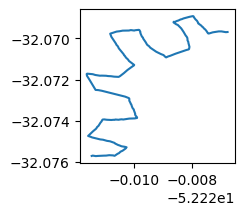

In [66]:
plt.figure(figsize=(2,2))
plt.plot(longitude, latitude)

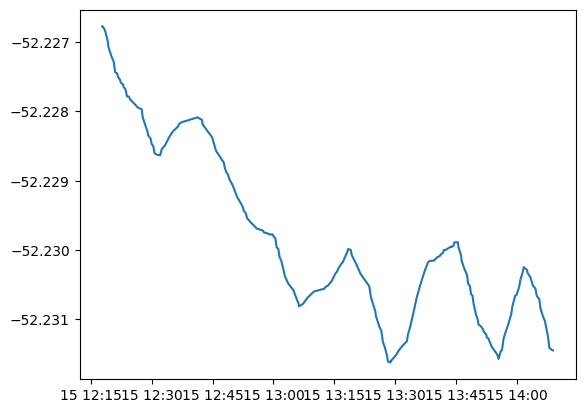

In [67]:
plt.plot(tempo, longitude)

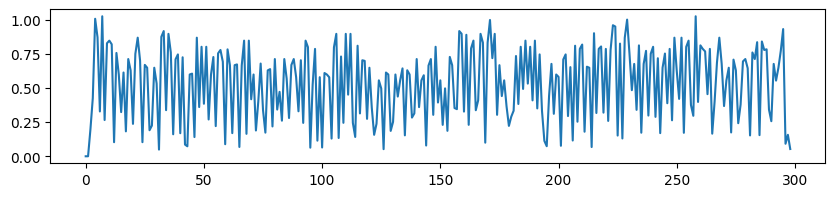

In [68]:
longitude = np.array(longitude)
latitude = np.array(latitude)

distancia = (np.diff(longitude)**2 + np.diff(latitude)**2) **.5  * 111120

tempo_n = mdates.date2num(tempo) * 24*60*60
dt = np.diff(tempo_n)

velocidade = distancia/dt

plt.figure(figsize=(10,2))
plt.plot(velocidade)


In [69]:
hoje = datetime.datetime(2026, 9, 10, 15, 41, 45)
hoje

datetime.datetime(2026, 9, 10, 15, 41, 45)

In [70]:
mdates.date2num(hoje)

np.float64(20706.653993055555)